<a href="https://colab.research.google.com/github/asegura4488/MetodosComputacionales2026/blob/main/Semana12/RegresionLinealPesos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [22]:
N = 15
x = np.linspace(0, 10, N)
b_real = 2.0
m_real = 1.8

sigma_y = 1/(0.2 + 0.1*x)

y_real = b_real + m_real * x
y = y_real + np.random.normal(0, sigma_y, N)

<ErrorbarContainer object of 3 artists>

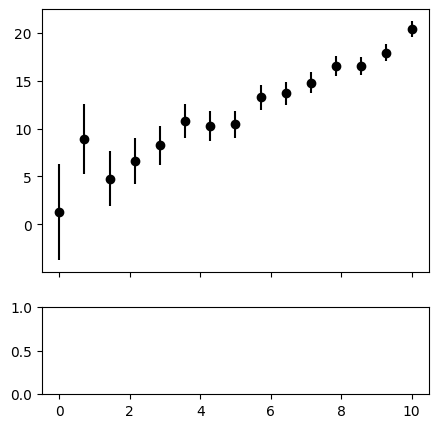

In [23]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')

In [24]:
# Programar minimos cuadrados ponderados
X = np.column_stack((np.ones(N),x))
X

array([[ 1.        ,  0.        ],
       [ 1.        ,  0.71428571],
       [ 1.        ,  1.42857143],
       [ 1.        ,  2.14285714],
       [ 1.        ,  2.85714286],
       [ 1.        ,  3.57142857],
       [ 1.        ,  4.28571429],
       [ 1.        ,  5.        ],
       [ 1.        ,  5.71428571],
       [ 1.        ,  6.42857143],
       [ 1.        ,  7.14285714],
       [ 1.        ,  7.85714286],
       [ 1.        ,  8.57142857],
       [ 1.        ,  9.28571429],
       [ 1.        , 10.        ]])

In [25]:
w = 1/sigma_y**2
w

array([0.04      , 0.07367347, 0.11755102, 0.17163265, 0.23591837,
       0.31040816, 0.39510204, 0.49      , 0.59510204, 0.71040816,
       0.83591837, 0.97163265, 1.11755102, 1.27367347, 1.44      ])

In [26]:
# Ecuaciones de minimos cuadrados
A = X.T @ (w[:,None]*X)
B = X.T @ (w*y)

In [27]:
A

array([[  8.77857143,  63.89285714],
       [ 63.89285714, 513.80830904]])

In [28]:
B

array([ 133.59281423, 1050.25701539])

In [29]:
beta_hat = np.linalg.solve(A,B)
beta_hat

array([3.58980826, 1.59766569])

In [30]:
b,m = beta_hat
_x = np.linspace(0,10,100)
_y = b + m*_x

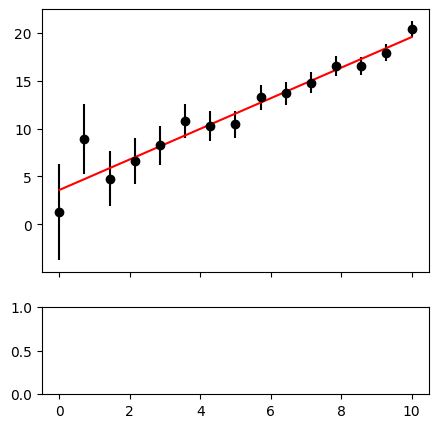

In [31]:
fig, (ax1,ax2) = plt.subplots(
    2,1,figsize=(5,5), sharex = True,
    gridspec_kw={'height_ratios': [3, 1]}
)
ax1.errorbar(x, y, yerr=sigma_y, fmt='o', color='k')
ax1.plot(_x,_y,color='r')

In [32]:
# Queremos calcular el error en los modelos
C_beta = np.linalg.inv(A)
C_beta

array([[ 1.19990988, -0.14921065],
       [-0.14921065,  0.02050083]])

In [33]:
error_b, error_m = np.sqrt( np.diag(C_beta) )

In [36]:
print(b,error_b)

3.589808264323103 1.0954039822072628


In [37]:
print(m,error_m)

1.5976656942856273 0.14318109434379095
